# numpy / matplotlib - Introduction : Théorie

## But du laboratoire
L'objectif est d'apprendre à utiliser les librairies `numpy` et `matplotlib` pour manipuler des tableaux, effectuer du calcul matriciel et afficher des graphiques simples.


## 1) Bases de numpy
Numpy permet le calcul numérique efficace avec des vecteurs et des matrices.
Dans la suite, on va appeler ce type de variable `array`. 
Pour commencer, regardons comment créer un `array` à partir d'une liste.


In [10]:
import numpy as np
a1 = np.array([1, 2, 3])     # création d'un array d'entiers à partir d'une liste
a2 = np.array([1, 2.0, 3])   # création d'un array de nombres en virgule flottante à partir d'une liste
print(type(a1[0]))
print(type(a2[0]))           # un seul flottant dans la liste provoque des flottants pour tous les éléments de l'array 


<class 'numpy.int64'>
<class 'numpy.float64'>


In [11]:
v = np.array([2, 3, 4], dtype=complex)  # on peut aussi forcer un type pour tous les éléments d'un array
print(v[0].real, v[0].imag)

2.0 0.0


On voit que tous les éléments d'un array ont toujours le même type; il s'agit d'une structure homogène, ce qui permet à Python de stocker le contenu d'un array de manière contigue en mémoire. Ceci explique l'efficacité de la librairie `numpy`.

Un array est fait pour `calculer` avec, ce qui n'est pas le cas pour une liste.

Exemple :

In [12]:
l1 = [1, 2, 3]
l2 = l1*2    # concaténation de deux listes identiques, pas multiplier par deux !
print(l2)

[1, 2, 3, 1, 2, 3]


In [13]:
l1 = [1, 2, 3]

v1 = np.array(l1)
v2 = v1*2   # chaque élément de l'array est multiplié par deux
print(v2) 

[2 4 6]


Les opérateurs `+`, `-`, `*`, `/`, `**` fonctionnent par définition `élément par élément` sur des arrays de taille identique. Exception : on peut p.ex. additionner une constante élément par élément sur un array.
Exemple :
 

In [14]:
l1 = [1, 2, 3]

v1 = np.array(l1)

v1 = v1-1
print(v1)
v1_inv = 1/v1
print(v1_inv)

[0 1 2]
[inf 1.  0.5]


C:\Users\mimod\AppData\Local\Temp\ipykernel_34972\774098368.py:7: RuntimeWarning: divide by zero encountered in divide
  v1_inv = 1/v1


On voit qu'il est possible d'inverser un array élément par élément.
Ici le premier élément `1/0` donne `inf`.

Une fonction mathématique quelconque s'applique également élément par élément.

Exemple :


In [6]:
x = np.array([4, 9, 25])
y = np.sqrt(x)             # calculer la racine carrée, élément par élément
print(y)

[2. 3. 5.]


Pour faire le produit scalaire entre deux vecteurs, on peut soit utiliser la fonction `np.dot()` ou bien l'opérateur `@`. 
Normalement, le produit scalaire se fait entre un vecteur ligne et un vecteur colonne, mais numpy ne fait pas de différence entre 1 ligne et 1 colonne. 

Exemple :

In [7]:
v1 = np.array([1/3, 2, 4])
v2 = np.array([3, 3, -1])
sc = v1 @ v2  # produit scalaire (1/3)*3 + 2*3 +4*(-1) = 1 + 6 - 4 = 3
print(sc)


3.0


Regardons maintenant comment on peut entrer une matrice M, en l'occurrence de taille 3x3, et la multiplier par un vecteur de taille 3x1. Notez qu'on calcule trois fois un produit scalaire, entre la première ligne de la matrice et le vecteur, entre la deuxième ligne de la matrice et le vecteur, et finalement entre la troisième ligne de la matrice et le vecteur.


In [8]:
M = np.array([[2, 3, 5], 
             [1, 1, -1],
             [0, 7, 11]])
print(M @ v2)


[10  7 10]


Pour accéder aux éléments d'un array à deux dimensions il faudra deux indices, le premier étant l'indice de la ligne, et le deuxième celui de la colonne. Les indices commencent avec zéro. Exemples :


In [9]:
print(M[1, 2]) # deuxième ligne, troisième colonne


-1


In [10]:
v1 = M[:, 0]  # extraire la première colonne
print(v1)

[2 1 0]


## 2) Création d'arrays particuliers
- `np.zeros` permet de créer des arrays de taille donnée remplis de zéros (0), p.ex. np.zeros((2, 3))
- `np.ones` permet de créer des arrays de taille donnée remplis de uns (1), p.ex. np.ones((2, 3))
- `np.full` permet de créer des arrays de taille donnée remplis d'une constante, p.ex. np.full((2, 3), 3.14)
- `np.linspace` permet de créer des arrays 1D à espacement linéaire constant, np.linspace(start, stop, nombre)
- `np.arange` permet de créer des arrays 1D à espacement linéaire constant, np.arange(start, stop, incrément)
- `np.logspace` permet de créer des arrays 1D à espacement logarithmique constant, np.logspace(start, stop, nombre)
- `np.random.normal` permet de créer des arrays de taille donnée remplie de nombres aléatoires avec une distribution gaussienne

Cette dernière commande permet p.ex. de simuler l'influence d'un bruit de mesure.

Exemples :

In [11]:
print(np.zeros((2, 3)))          # matrice de taille 2 x 3 remplie avec la valeur 0
print(np.full((2, 3), 3.14))     # matrice de taille 2 x 3 remplie avec la valeur 3.14
print(np.linspace(-1, 3, 9))     # vecteur de longueur 9 à espacement linéaire commençant à -1 et finissant à 3
print(np.logspace(-1, 2, 4))     # vecteur de longueur 4 à espacement logarithmique commençant à 10**(-1) et finissant à 10**2
print(np.random.normal(loc = 1.0, scale = 2.0, size = (2, 3))) # matrice de taille 2x3 remplis avec valeurs aléatoires de moyenne 1.0 et écart type 2.0

[[0. 0. 0.]
 [0. 0. 0.]]
[[3.14 3.14 3.14]
 [3.14 3.14 3.14]]
[-1.  -0.5  0.   0.5  1.   1.5  2.   2.5  3. ]
[  0.1   1.   10.  100. ]
[[2.96956364 0.96589494 4.82347166]
 [1.71296764 0.55685271 1.75374216]]


## 3) Résolution de systèmes linéaires
En ingénierie, dans n'importe quel domaine, on a souvent la notion de systèmes linéaires pour lesquels le principe de superposition s'applique.
Quelques exemples :
- Une structure mécanique flexible soumise à plusieurs forces, et on aimerait calculer les déformations de la structure à plusieurs endroits,
- un circuit électrique RLC compliqué, p.ex. un réseau électrique dans lequel il y a plusieurs sources, et on aimerait calculer les courants dans plusieurs branches.
Ce domaine mathématique très important pour l'ingénierie s'appelle l'algèbre linéaire.
On a typiquement un nombre $n$ d'inconnues et un nombre $n$ d'équations linéaires.

Example d'un système linéaire avec 3 inconnues $x_1, x_2$ et $x_3$ :
\begin{align*}
x_1 + 2 x_2 - x_3 &=& 1 \\
3 x_1 + 5 x_2  &=& 7 \\
-x_1 + 7 x_2 - 11 x_3 &=& 0
\end{align*}

Pour résoudre, on va écrire ce système sous forme matricielle $\bf A \bf x = \bf b$, où on regroupe les trois inconnues $x_1, x_2$ et $x_3$ dans un vecteur colonne $\bf x$, puis les coefficients dans une matrice $\bf A$,
\begin{align*}
\bf A = \left[
\begin{array}{rrr}
1 & 2 & -1 \\
3 & 5 & 0 \\
-1 & 7 & -11
\end{array}
\right]
\end{align*},
et le côté droit du système dans un vecteur colonne $\bf b$
\begin{align*}
\bf b = \left[
\begin{array}{r}
1 \\
7 \\
0
\end{array}
\right].
\end{align*}
Vous avez (ou bien vous allez) apprendre en math comment résoudre un tel problème à la main : si $\det(\bf A) \ne 0$, la matrice $\bf A$ est inversible, et la solution de $\bf A \bf x = \bf b$ s'écrit $\bf x = \bf A^{-1} \bf b$. 
Vous avez (ou bien vous allez) apprendre en math comment calculer à la main l'inverse d'une matrice si elle existe.
Dans numpy il y a la fonction `np.linalg.inv()` pour calculer l'inverse d'une matrice, mais il s'avère qu'il y a une solution plus élégante.
Pour résoudre ce système linéaire avec numpy, pour autant qu'il y aie une solution, on procède de la manière suivante :

In [12]:
A = np.array([[1, 2, -1],
              [3, 5, 0],
              [-1, 7, -11]])

b = np.array([1,
              7,
              0])
x = np.linalg.solve(A, b)
print(x)



[-3.33333333  3.4         2.46666667]


Pour tester si le vecteur $\bf x$ trouvé est correct, mieux vaut être méfiant, on peut calculer $\bf A \bf x - \bf b$ et puis voir si ça donne le vecteur zéro.
 

In [13]:
residu = A @ x - b
print(residu)
print(np.linalg.norm(residu))  # la norme Euclidienne du vecteur résidu devrait être zéro


[0.0000000e+00 0.0000000e+00 4.4408921e-16]
4.440892098500626e-16


Dû aux arrondis avec les nombres en virgule flottante, on n'a pas pile poil zéro, mais presque zéro, ce qui nous confirme que la solution $\bf x$ trouvée est numériquement correcte.

On a souvent en ingénierie des systèmes linéaires avec un nombre très élevé d'inconnues, mais le temps de calcul pour résoudre avec numpy reste très faible.

Exemple :

In [14]:
A = np.random.normal(size=(1000, 1000))  # une matrice A aléatoire de taille 1'000 x 1'000, donc un million de nombres en virgule flottante à stocker !
b = np.random.normal(size=(1000, 1))     # 1'000 équations avec 1'000 inconnues !

import time
t_ini = time.time()                 # début du chronométrage du temps de calcul
x = np.linalg.solve(A, b)
temps_calcul = time.time() - t_ini  # temps de calcul
print(temps_calcul)  # ça prend que quelques dixièmes de secondes pour trouver les 1'000 inconnues !

print(np.linalg.norm(A @ x - b))  # contrôle si la solution est correcte, à l'arrondi près

0.5922760963439941
1.6761344193304504e-10


## 4) Régression linéaire et résolution de problèmes aux moindres carrés (least squares)

On a souvent le problème de trouver une courbe qui approxime des données bruités.
La courbe ne va typiquement pas passer exactement par les points.
Example : trouver une droite dans le plan qui colle au mieux à 3 points (ou plus).
Il s'agit d'un système linéaire surdéterminé où il y a plus d'équations que d'inconnues.
En règle générale, il n'y a pas de solution exacte, mais on peut essayer de trouver une solution approximative dans le sens d'un problème d'optimisation. Considérons la situation ci-dessous, où on aimerait trouver l'équation de la droite de régression qui passe "au mieux" par les 3 points 
$\bf P_1 = (0, 1), \bf P_2 = (1, 2),$ et $\bf P_3 = (2, 4)$.
<img src="F1.png" alt="" style="width: 25vw; margin: 20px"/>

Soit l'équation de la droite $z = \alpha w + \beta$, où $\alpha$ dénote la pente de la droite, et $\beta$ l'offset.
Si la droite passe exactement par $\bf P_3$, cela se traduirait par 
$2 \alpha + \beta = 4$.
On se rend compte qu'il est impossible de faire passer la droite simulatanément par les trois point, et donc on va introduire un résidu par équation, et pour le point $\bf P_3$, on obtient $2 \alpha + \beta = 4 + r_3$.
On obtient le système linéaire ci-dessous :
\begin{align*}
0 \alpha + 1 \beta &=& 1 + r_1 \\
1 \alpha + 1 \beta  &=& 2 + r_2 \\
2 \alpha + 1 \beta  &=& 4 + r_3
\end{align*}
Pour que la droite passe au mieux par les points, on souhaite que les résidus soient faibles.
Plus précisément on va essayer de trouver $\alpha$ et $\beta$ de telle manière à minimiser $r_1^2 + r_2^2 + r_3^2$.
C'est pour cette raison que la méthode s'appelle la méthodes des moindres carrés (least squares).
On va écrire ce problème d'optimisation sous forme matricielle $\min_{\bf x} ||\bf A \bf x - \bf b||$, où on regroupe les deux inconnues $\alpha$ et $\beta$ dans un vecteur colonne $\bf x$, puis les coefficients dans une matrice $\bf A$,
\begin{align*}
\bf A = \left[
\begin{array}{rr}
0 & 1  \\
1 & 1 \\
2 & 1 
\end{array}
\right]
\end{align*},
et le côté droit du système dans un vecteur colonne $\bf b$
\begin{align*}
\bf b = \left[
\begin{array}{r}
1 \\
2 \\
4
\end{array}
\right].
\end{align*}
Sans entrer dans la solution mathématique, ni dans l'algorithme de résolution, on obtient la solution optimale avec numpy de la manière suivante :

In [15]:
A = np.array([[0, 1],
              [1, 1],
              [2, 1]])

b = np.array([1,
              2,
              4])
x = np.linalg.lstsq(A, b, rcond=None)[0]
print(x)
alpha = x[0]  # pente de la droite de régression
beta = x[1]   # offset de la droite de régression


[1.5        0.83333333]


### 5) Polynômes dans numpy 

Nous allons utiliser le subpackage numpy.polynomial pour manipuler les polynômes.
Pour des raisons pratiques, nous recommandons de l'importer avec la commande

`from numpy.polynomial import Polynomial`

Un polynôme est essentiellement représenté par un `array` dans lequel se trouvent ses coefficients, en commençant par le coefficient de la puissance la plus basse. Le premier élément de l'array correspond donc au terme constant (qui peut être zéro; dans ce cas il faudra mettre zéro).
Le nom de la variable indépendante n'apparaît pas !
S'il y a des puissances qui manquent, il faudra impérativement mettre des zéros pour les coefficients des termes manquants, p.ex. le polynôme $x^3 - x + 5$ est saisi par 

`coeff = np.array([5, -1, 0, 1])`

`p3 = Polynomial(coeff)`.

Les fonctions de bases pour manipuler les polynômes sont réalisées via les `méthodes` suivantes :

- `p3(x)` permet d'évaluer le polynôme `p3` sur les abscisses de l'array `x` 
- `p3.roots()` permet de calculer les racines du polynôme `p3`.
- `p3.deriv()` permet de caluler la dérivée du polynôme `p3` ce qui correspond à un polynôme de degré - 1 
- `p3.integ()` permet de caluler l'intégrale du polynôme `p3` ce qui correspond à un polynôme de degré + 1 

### 6) Visualisation de données avec Matplotlib
<img src="matplotlib.png" alt="" style="width: 40vw; margin: 20px"/>

La librairie Matplotlib permet de visualiser des données sous forme de graphiques, p.ex.

- visualiser des points dans un plan,
- visualiser l'allure d'une fonction à une variable, 
- visualiser les courbes de niveau d'une fonction à 2 variables,
- visualiser une surface plongée dans $R^3$, 
- visualiser un champ vectoriel dans $R^2$ ou $R^3$,
- visualiser un histogramme,
- visualiser un diagramme en toile d'araignée,
- visualiser des objets en 3D,
- animer des objets en 3D,
- etc.

Ici, nous allons nous concentrer que sur les fonctionnalités de base de Matplotlib.

La visualisation est basée sur une numérisation préalable (calculer des points).

Pour visualiser des points dans l'espace, on a besoin d'un array avec les abscisses, et un array de même taille avec les ordonnées.
Exemple :

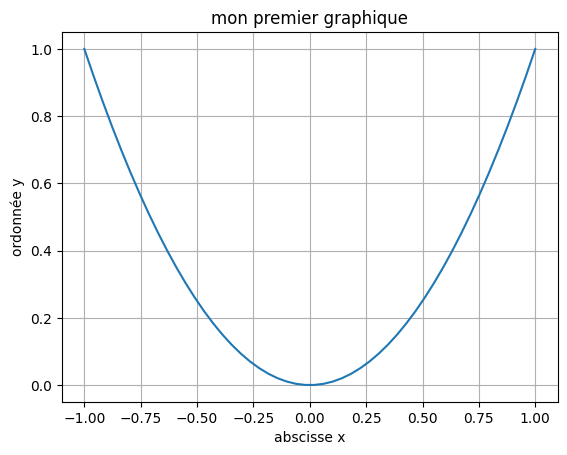

In [5]:
import matplotlib.pyplot as plt
x = np.linspace(-1, 1, 50)  # 50 valeurs espacées linéairement entre -1 et 1
y = x**2
plt.plot(x, y)   # afficher la parabole
plt.title("mon premier graphique")
plt.xlabel("abscisse x")
plt.ylabel("ordonnée y")
plt.grid()   # enclencher la grille

Par défaut, `plot()` relie les points par des segments de droite.
On peut également plotter que les points, sans les relier.
Ceci est particulièrement utile pour visualiser des mesures
Exemple :

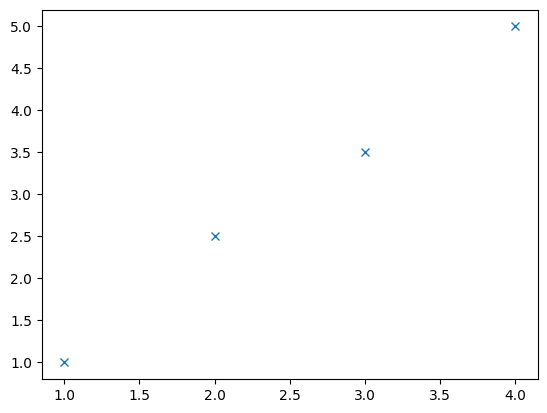

In [9]:
x1 = np.array([1, 2, 3, 4])
y1 = np.array([1, 2.5, 3.5, 5])
plt.plot(x1, y1, 'x')   # afficher les points avec des x


On peut superposer plusieurs graphiques, par exemple rajouter une droite de régression sur des points mesurés.

In [1]:
from numpy.polynomial import Polynomial
degree = 1

# methode 1 : calculer les coefficients avant la création du polynôme
coeff = np.polynomial.polynomial.polyfit(x1, y1, degree)
p1 = Polynomial(coeff)
yreg = p1(x1)
print(p1)

# methode 2 : création du polynôme directement
p1bis = Polynomial.fit(x1, y1, degree)
yregbis = p1bis(x1)
print(p1bis.convert().coef)



print(yregbis-yreg)
plt.plot(x1, y1, 'x', x1, yreg,x1,yregbis,'o')

NameError: name 'np' is not defined